In [3]:
import sys
sys.path.append('../../')

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from QGP.Soliton_Gen import soliton
from scipy.optimize import minimize_scalar
from time import time

plt.style.use('bmh')

plt.rcParams['figure.figsize'] = (7, 5)
plt.rcParams['legend.fontsize'] = 14
plt.rcParams["axes.titlesize"] = 24
plt.rcParams["axes.labelsize"] = 18
plt.rcParams["figure.titlesize"] = 24
plt.rcParams["ytick.labelsize"] = 14
plt.rcParams["xtick.labelsize"] = 14
plt.rcParams['savefig.facecolor'] = 'white'
plt.rcParams["axes.formatter.useoffset"]= False

Creating soliton...
Soliton created


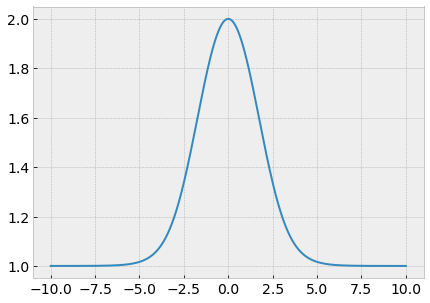

In [6]:
c = 2 #np.sqrt(2)/2
k = 1
sol, x = soliton(c, k, soliton_type="anti", L=10, N=1_000)
plt.plot(x, np.abs(sol**2))
plt.show()

# Dark Soliton in $D_1$

In [313]:
# Function to invert

def F_c_k(y, c, k):
    
    # Domain
    ymin = 0
    ymax = 1-c*c/2
    
    y = np.asarray(y)
    
    valid_mask = (y > ymin) & (y <= ymax)
    
    # Assign infinite to values outside the domain
    val = np.full_like(y, np.inf, dtype=np.float64)
    val[y > ymax] = -np.inf
    
    def f_c_k(y):
        root = np.sqrt((2-c*c-2*y)/(1-2*k+2*k*y))
        sum_1 = 2 * np.sqrt(k) * np.arctan(np.sqrt(k) * root)
        sum_2 = 2 * np.sqrt((1-2*k)/(2-c*c)) * np.arctanh(np.sqrt((1-2*k)/(2-c*c)) * root)
        output = sum_1 + sum_2
        return output
    
    val[valid_mask] = f_c_k(y[valid_mask])
    
    return val

c = 0.7071067811865476 k = [0.0625 0.125  0.1875 0.25   0.3125 0.375  0.4375]


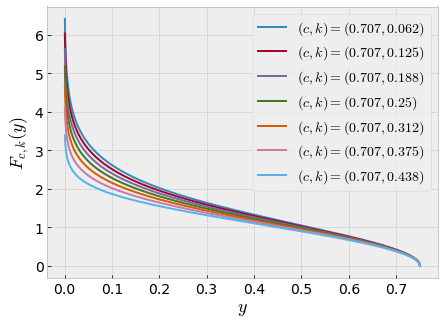

In [314]:
### Varying k ###

N = 8
c = np.sqrt(2)/2
ks = np.linspace(0, 1/2, N, endpoint=False)[1:]
print("c =", c, "k =", ks)

y_to_plot = np.linspace(0, 1-c*c/2, 1_000)

for k in ks:
    plt.plot(y_to_plot, F_c_k(y_to_plot, c, k), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))))
    plt.legend()

plt.xlabel(r"$y$")
plt.ylabel(r"$F_{c, k}(y)$")
plt.show()

c = [0.         0.1767767  0.35355339 0.53033009 0.70710678 0.88388348
 1.06066017 1.23743687] k = 0.25


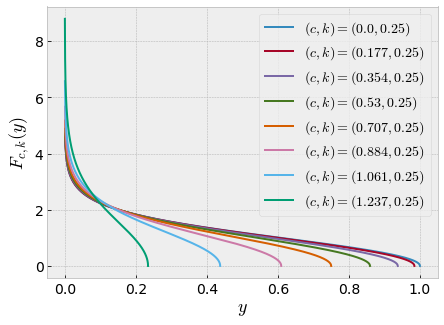

In [315]:
### Varying c ###

N = 8
cs = np.linspace(0, np.sqrt(2), N, endpoint=False)
k = 1/4
print("c =", cs, "k =", k)

for c in cs:
    y_to_plot = np.linspace(0, 1-c*c/2, 1_000)[1:]
    plt.plot(y_to_plot, F_c_k(y_to_plot, c, k), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))))
    plt.legend()
    
plt.xlabel(r"$y$")
plt.ylabel(r"$F_{c, k}(y)$")
plt.show()

## Dark soliton

In [316]:
def _get_valid_refpoints(xmin, xmax):
    d = xmax - xmin
    ref1 = xmin + d / 4.
    ref2 = xmax - d / 4.
    return ref1, ref2

In [317]:
import warnings

## eta_c_k generator

def eta_c_k(x, c, k, even=True):
    
    # Domain
    ymin = 0
    ymax = 1-c*c/2
    
    ref1, ref2 = _get_valid_refpoints(ymin, ymax)
    
    min_kwargs = {}
    min_kwargs['bracket'] = (ref1, ref2)
    min_kwargs['tol'] = 1.48e-12
    min_kwargs['method'] = 'Golden'
    
    x = np.asarray(x)
    N = x.size
    m = N//2
    
    xpos = x[N//2:]
    
    F_to_inv = lambda y: F_c_k(y, c, k)
    
    results = np.full_like(x, np.nan, dtype=np.float64)
    resultsmask = np.zeros(x. shape, dtype=bool)
    
    for j in range(xpos.size):
        
        if F_to_inv(ymax) == xpos[j]:
            results[N//2+j] = ymax
        
        if F_to_inv(ymin) == xpos[j]:
            results[N//2+j] = ymin
        
        optimizer = (lambda x, j=j,
                        bounded_f=F_to_inv: (np.abs(F_to_inv(x) - xpos[j]))**2)
        
        try:
            with warnings.catch_warnings(record=True):
                result = minimize_scalar(optimizer, **min_kwargs)

            results[N//2+j] = result.x
            resultsmask[N//2+j] = result.success

        except:
            resultsmask[N//2+j] = False

    if any(~resultsmask[N//2:]):
            warnings.warn("Trouble calculating inverse for values: "
                          "%s" % str(xpos[~resultsmask[N//2:]]), RuntimeWarning)   
    try:
        np.testing.assert_array_almost_equal(xpos, F_to_inv(results[N//2:]), decimal=2)

    except AssertionError:
        warnings.warn("Results obtained with less than %g "
                          "decimal digits of accuracy"
                          % 2, RuntimeWarning)

    if even:
        results[:N//2] = np.flip(results[N//2:])
        return results
    
    return results[N//2:]


c = 0.7071067811865476 k = [0.125 0.25  0.375]


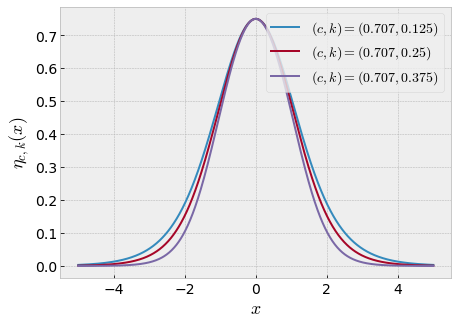

In [318]:
#import warnings
#warnings.filterwarnings("ignore")

### Invert function ###

### Varying k ###

N = 4
c = np.sqrt(2)/2
ks = np.linspace(0, 1/2, N, endpoint=False)[1:]
print("c =", c, "k =", ks)

L = 5
x = np.linspace(-L, L, 1_000)

for k in ks:
    
    plt.plot(x, eta_c_k(x, c, k), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))))
    plt.legend()

plt.xlabel(r"$x$")
plt.ylabel(r"$\eta_{c, k}(x)$")
plt.show()

In [320]:
print("c = ", c, "k = ", k)
Ns = np.array([2**(j) for j in range(2, 11)])
hs = []
errors = [] #np.zeros(len(Ns))
xs = []
L = 5

for j in range(len(Ns)):
    N = Ns[j]
    x = np.linspace(-L, L, N)
    eta = eta_c_k(x, c, k, even=False)
    
    x_pos = x[N//2:]
    h = x_pos[1] - x_pos[0]
    hs += [h]
    F_eta = F_c_k(eta, c, k)
    error = np.abs(x_pos - F_eta)
    
    errors += [error]
    xs += [x_pos]
    
hs = np.array(hs)

c =  0.7071067811865476 k =  0.375


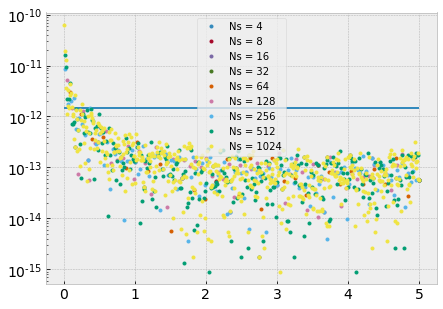

In [321]:
for j in range(len(errors)):
    plt.plot(xs[j], errors[j], ".", label="Ns = {}".format(Ns[j]))
#plt.plot(hs, hs**-0.8 * np.exp(-28))
plt.legend(fontsize=10)
plt.hlines(1.48e-12, 0, 5)
plt.yscale("log")
#plt.xscale("log")
plt.show()

In [325]:
print("c = ", c, "k = ", k)
Ns = np.array([2**(j) for j in range(2, 11)])
hs = []
errors = [] #np.zeros(len(Ns))
ys = []
L = 5

for j in range(len(Ns)):
    N = Ns[j]
    y = np.linspace(0, 1-c*c/2, N)[1:]
    F_ = F_c_k(y, c, k)
    F_ = np.append(np.flip(F_), F_)
    eta = eta_c_k(F_, c, k, even=False)
    error = np.abs(y - eta)
    
    errors += [error]
    ys += [y]
    
hs = np.array(hs)

c =  0.7071067811865476 k =  0.375


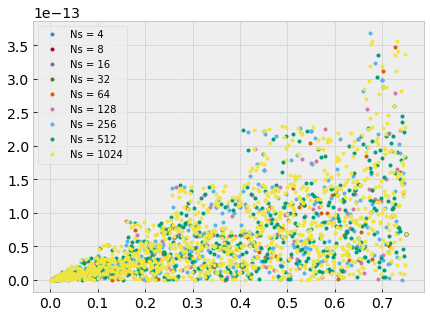

In [326]:
for j in range(len(errors)):
    plt.plot(ys[j], errors[j], ".", label="Ns = {}".format(Ns[j]))
#plt.plot(hs, hs**-0.8 * np.exp(-28))
plt.legend(fontsize=10)
#plt.hlines(1.48e-12, 0, 5)
#plt.yscale("log")
#plt.xscale("log")
plt.show()

c = [0.         0.35355339 0.70710678 1.06066017] k = 0.25


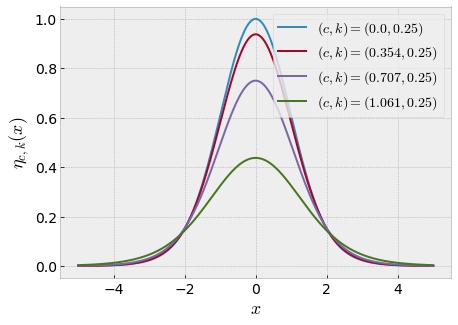

In [162]:
### Varying c ###

N = 4
cs = np.linspace(0, np.sqrt(2), N, endpoint=False)
k = 1/4
print("c =", cs, "k =", k)

L = 5
x = np.linspace(-L, L, 1_000)

for c in cs:
    
    plt.plot(x, eta_c_k(x, c, k), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))))
    plt.legend()

plt.xlabel(r"$x$")
plt.ylabel(r"$\eta_{c, k}(x)$")
plt.show()

In [328]:
## Solitons in variable u

def rho_c_k(x, eta):
    output = np.sqrt(1 - eta)
    return output
    

def theta_c_k(x, c, eta):
    
    ## Function to integrate
    integrand = eta/(1 - eta)
    
    N = x.size
    m = N//2
    xpos = x[m:]
    theta = np.zeros(N)
    
    dx = xpos[1] - xpos[0]
    
    theta[m] = 0
    
    for j in range(m-1):
        
        theta[j+1+m] = theta[j+m] + c/2 * (dx/2 * (integrand[j+m] + integrand[j+m+1]))
    
    theta[:m] = np.flip(theta[m:])
    
    return theta


def u_c_k(x, c, eta):
    i = 1j
    
    if c == 0:
        output = np.sign(x) * np.sqrt(1 - eta)
        return output
    
    rho = rho_c_k(x, eta)
    theta = theta_c_k(x, c, eta)
    return rho * np.exp(i*theta)

def norm(x):
    return np.abs(x)**2

c = 0.7071067811865476 k = [0.1 0.2 0.3 0.4]


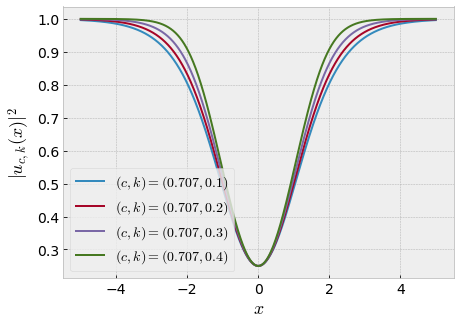

In [329]:
### Varying k ###

N = 5
c = np.sqrt(2)/2 #0
ks = np.linspace(0, 1/2, N, endpoint=False)[1:]
print("c =", c, "k =", ks)


L = 5
x = np.linspace(-L, L, 2_000)


for k in ks:
    eta = eta_c_k(x, c, k)
    plt.plot(x, norm(u_c_k(x, c, eta)), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))))
    plt.legend()

plt.xlabel(r"$x$")
plt.ylabel(r"$|u_{c, k}(x)|^2$")
plt.show()

c = [0.         0.35355339 0.70710678 1.06066017] k = 0.25


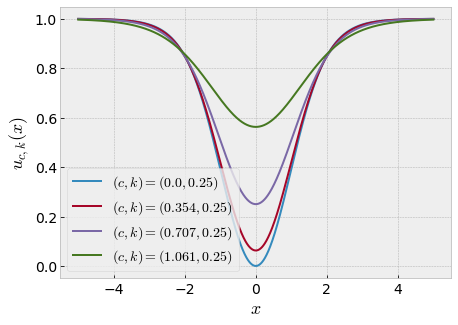

In [330]:
### Varying c ###

N = 4
cs = np.linspace(0, np.sqrt(2), N, endpoint=False)
k = 1/4
print("c =", cs, "k =", k)

L = 5
x = np.linspace(-L, L, 2_000)

for c in cs:
    eta = eta_c_k(x, c, k)
    plt.plot(x, norm(u_c_k(x, c, eta)), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))))
    plt.legend()

plt.xlabel(r"$x$")
plt.ylabel(r"$u_{c, k}(x)$")
plt.show()

# Anti-Dark Solitons in $D_3$

In [331]:
# Function to invert
def H_c_k(y, c, k):
    
    # Domain
    ymin = 1-c*c/2
    ymax = 0
    
    y = np.asarray(y)
    
    valid_mask = (y >= ymin) & (y < ymax)
    
    # Assign infinite to values outside the domain
    val = np.full_like(y, -np.inf, dtype=np.float64)
    val[y > ymax] = np.inf
    
    def h_c_k(y):
        root = np.sqrt((2-c*c-2*y)/(1-2*k+2*k*y))
        sum_1 = 2 * np.sqrt(k) * np.arctan(np.sqrt(k) * root)
        sum_2 = 2 * np.sqrt((1-2*k)/(2-c*c)) * np.arctanh(np.sqrt((1-2*k)/(2-c*c)) * root)
        output = sum_1 + sum_2
        return output
    
    val[valid_mask] = h_c_k(y[valid_mask])
    
    return val

c = 2 k = [1.14285714 1.78571429 2.42857143 3.07142857 3.71428571 4.35714286
 5.        ]


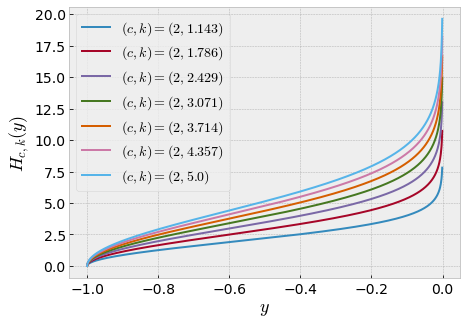

In [332]:
### Varying k ###

N = 8
c = 2
ks = np.linspace(1/2, 5, N)[1:]
print("c =", c, "k =", ks)

y_to_plot = np.linspace(1-c*c/2, 0, 1_000, endpoint=False)

for k in ks:
    plt.plot(y_to_plot, H_c_k(y_to_plot, c, k), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))))
    plt.legend()
    
plt.xlabel(r"$y$")
plt.ylabel(r"$H_{c, k}(y)$")
plt.show()

c = [1.92646877 2.43872397 2.95097918 3.46323438 3.97548959 4.48774479
 5.        ] k = 2


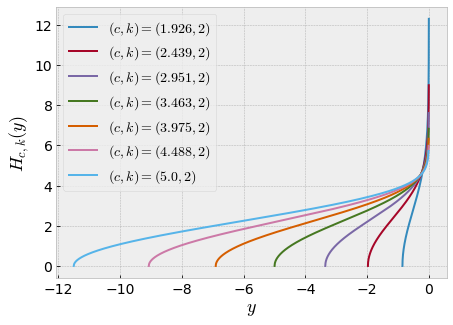

In [333]:
### Varying c ###

N = 8
cs = np.linspace(np.sqrt(2), 5, N)[1:]
k = 2
print("c =", cs, "k =", k)

for c in cs:
    y_to_plot = np.linspace(1-c*c/2, 0, 1_000, endpoint=False)
    plt.plot(y_to_plot, H_c_k(y_to_plot, c, k), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))))
    plt.legend()
    
plt.xlabel(r"$y$")
plt.ylabel(r"$H_{c, k}(y)$")
plt.show()

## Dark soliton

In [338]:
## eta_c_k generator

def eta_H_c_k(x, c, k, even=True):
    
    # Domain
    ymin = 1-c*c/2
    ymax = 0
    
    ref1, ref2 = _get_valid_refpoints(ymin, ymax)
    
    min_kwargs = {}
    min_kwargs['bracket'] = (ref1, ref2)
    min_kwargs['tol'] = 1.48e-12
    min_kwargs['method'] = 'Golden'
    
    x = np.asarray(x)
    N = x.size
    
    if N == 1:
        xpos = x
        
    else:
        xpos = x[N//2:]
    
    H_to_inv = lambda y: H_c_k(y, c, k)
    
    results = np.full_like(x, np.nan, dtype=np.float64)
    
    for j in range(xpos.size):
        
        if H_to_inv(ymax) == xpos[j]:
            results[N//2+j] = ymax
        
        if H_to_inv(ymin) == xpos[j]:
            results[N//2+j] = ymin
        
        optimizer = (lambda x, j=j,
                        bounded_f=H_to_inv: (np.abs(H_to_inv(x) - xpos[j]))**2)
        
        result = minimize_scalar(optimizer, **min_kwargs)
        results[N//2+j] = result.x
    
    if even:
        results[:N//2] = np.flip(results[N//2:])
        return results
    
    return results[N//2:]

c = 2 k = [1.14285714 1.78571429 2.42857143 3.07142857 3.71428571 4.35714286
 5.        ]


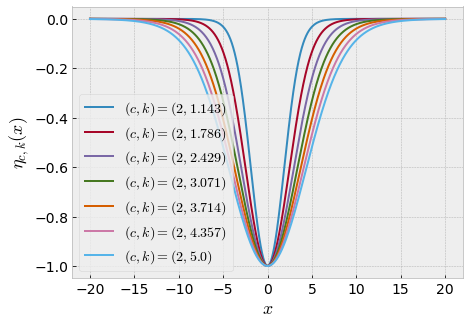

In [344]:
import warnings
#warnings.filterwarnings("ignore")

### Invert function ###

### Varying k ###

N = 8
c = 2
ks = np.linspace(1/2, 5, N)[1:]
print("c =", c, "k =", ks)

L = 20
x = np.linspace(-L, L, 1_000)


for k in ks:
    
    plt.plot(x, eta_H_c_k(x, c, k), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))))
    plt.legend()

plt.xlabel(r"$x$")
plt.ylabel(r"$\eta_{c, k}(x)$")
plt.show()

c = [1.92646877 2.43872397 2.95097918 3.46323438 3.97548959 4.48774479
 5.        ] k = 5


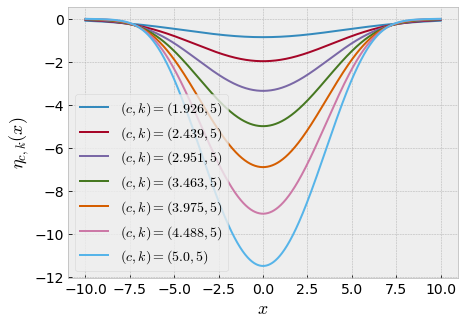

In [340]:
### Varying c ###

N = 8
cs = np.linspace(np.sqrt(2), 5, N)[1:]
k = 5
print("c =", cs, "k =", k)

L = 10
x = np.linspace(-L, L, 1_000)
xs = x[len(x)//2:]

for c in cs:
    
    plt.plot(x, eta_H_c_k(x, c, k), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))))
    plt.legend()

plt.xlabel(r"$x$")
plt.ylabel(r"$\eta_{c, k}(x)$")
plt.show()

In [357]:
c, k = 2, 5
print("c = ", c, "k = ", k)
Ns = np.array([2**(j) for j in range(2, 11)])
hs = []
errors = [] #np.zeros(len(Ns))
xs = []
L = 20

for j in range(len(Ns)):
    N = Ns[j]
    x = np.linspace(-L, L, N)
    eta = eta_H_c_k(x, c, k, even=False)
    
    x_pos = x[N//2:]
    h = x_pos[1] - x_pos[0]
    hs += [h]
    F_eta = H_c_k(eta, c, k)
    error = np.abs(x_pos - F_eta)
    
    errors += [error]
    xs += [x_pos]
    
hs = np.array(hs)

c =  2 k =  5


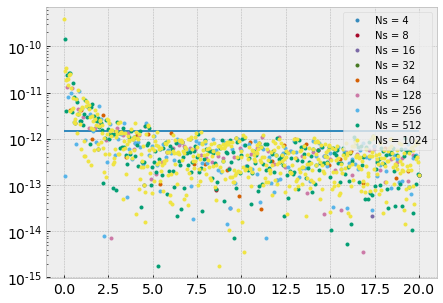

In [358]:
for j in range(len(errors)):
    plt.plot(xs[j], errors[j], ".", label="Ns = {}".format(Ns[j]))
#plt.plot(hs, hs**-0.8 * np.exp(-28))
plt.legend(fontsize=10)
plt.hlines(1.48e-12, 0, 20)
plt.yscale("log")
#plt.xscale("log")
plt.show()

In [367]:
print("c = ", c, "k = ", k)
Ns = np.array([2**(j) for j in range(2, 11)])
hs = []
errors = [] #np.zeros(len(Ns))
ys = []
L = 20

for j in range(len(Ns)):
    N = Ns[j]
    y = np.linspace(1-c*c/2, 0, N, endpoint=False)
    F_ = H_c_k(y, c, k)
    F_ = np.append(np.flip(F_), F_)
    eta = eta_H_c_k(F_, c, k, even=False)
    error = np.abs(y - eta)

    errors += [error]
    ys += [y]

hs = np.array(hs)

c =  2 k =  5


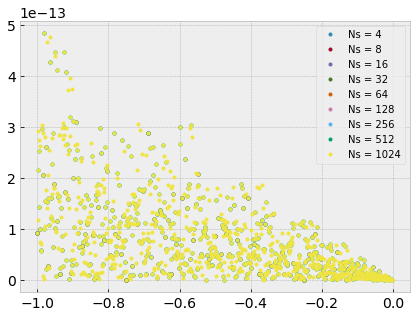

In [368]:
for j in range(len(errors)):
    plt.plot(ys[j], errors[j], ".", label="Ns = {}".format(Ns[j]))
#plt.plot(hs, hs**-0.8 * np.exp(-28))
plt.legend(fontsize=10)
#plt.hlines(1.48e-12, 0, 5)
#plt.yscale("log")
#plt.xscale("log")
plt.show()

c = 2 k = [1.625 2.75  3.875 5.   ]


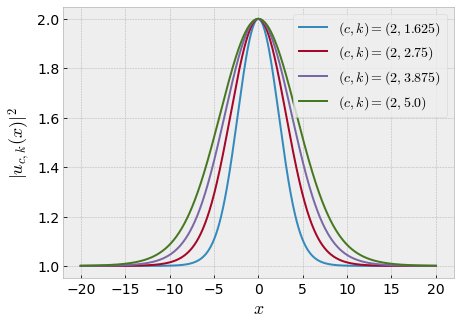

In [175]:
### Varying k ###

N = 5
c = 2
ks = np.linspace(1/2, 5, N)[1:]
print("c =", c, "k =", ks)


L = 20
x = np.linspace(-L, L, 2_000)


for k in ks:
    eta = eta_H_c_k(x, c, k)
    plt.plot(x, norm(u_c_k(x, c, eta)), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))))
    plt.legend()

plt.xlabel(r"$x$")
plt.ylabel(r"$|u_{c, k}(x)|^2$")
plt.show()

c = [2.31066017 3.20710678 4.10355339 5.        ] k = 2


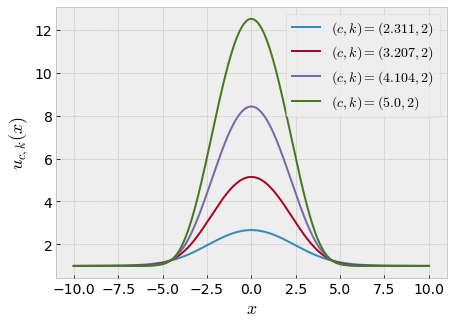

In [178]:
### Varying c ###

N = 5
cs = np.linspace(np.sqrt(2), 5, N)[1:]
k = 2
print("c =", cs, "k =", k)

L = 10
x = np.linspace(-L, L, 2000)

for c in cs:

    eta = eta_H_c_k(x, c, k)
    plt.plot(x, norm(u_c_k(x, c, eta)), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))))
    plt.legend()

plt.xlabel(r"$x$")
plt.ylabel(r"$u_{c, k}(x)$")
plt.show()
